# A09 - Optimización Bayesiana

|                |                  |
:----------------|------------------|
| **Nombre**     | Omar Mendoza     |
| **Fecha**      | 04/11/2026       |
| **Expediente** | 757806           |

**Teorema de Bayes**

$$ P(A|B) = \frac{P(B|A) P(A)}{P(B)} $$

$ P(A|B) $: Probabilidad condicional de A dado B. También conocida como la probabilidad posterior de A dado que B ocurre.

$ P(B|A) $: Probabilidad condicional de B dado A. Se interpreta como la verosimilitud (*likelihood*) de A.

$ P(A) $: Probabilidad de observar A. También conocida como probabilidad a priori.

$ P(B) $: Probabilidad de observar B. Interpretada como evidencia.

Utilizando las definiciones de arriba actualizamos la definición del teorema de bayes:

$$ \text{posterior} = \frac{(\text{verosimilitud})(\text{anterior})}{\text{evidencia}} $$

La intuición es que el teorema de Bayes es una herramienta para actualizar nuestras creencias dado lo que se tenía antes y nueva evidencia. Por ejemplo, tomas una moneda y asumes que es una moneda justa, dado que es lo más probable y que las monedas suelen ser justas en tu experiencia. Lanzas la moneda tres veces y cae sello las tres veces; un poco extraño, así que ajustas tus creencias y empiezas a imaginar que la moneda no es tan justa como debería ser. Lanzas las monedas tres veces y cae águila; ahora crees que la moneda es justa de nuevo.

## ¿Cómo aplicamos esto en nuestra vida diaria?

Imagina que tienes 3 puntos (conocimiento previo) en un espacio.

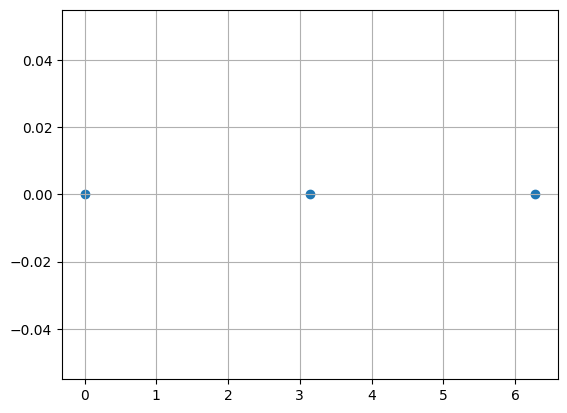

In [1]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(); plt.scatter([0, np.pi, 2*np.pi], [0, 0, 0]); plt.grid()

No hay seguridad de cómo se conectan estos puntos, pero sabes que están conectados. Hay infinitas formas en las que estos puntos se pueden conectar.

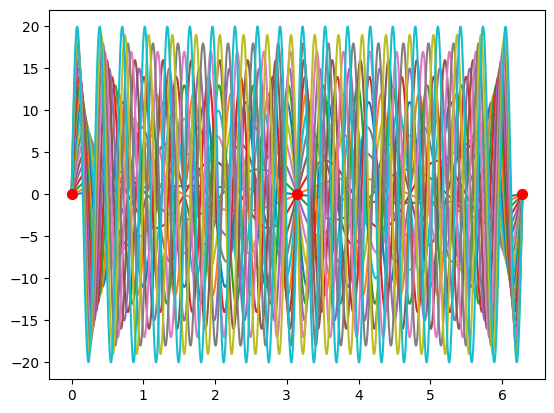

In [2]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(20) :
    y = (i+1)*np.sin((i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi], [0, 0, 0], s=50, c="r", zorder=3)

Hay tanta incertidumbre que decides pedir más información y te dan otro punto.

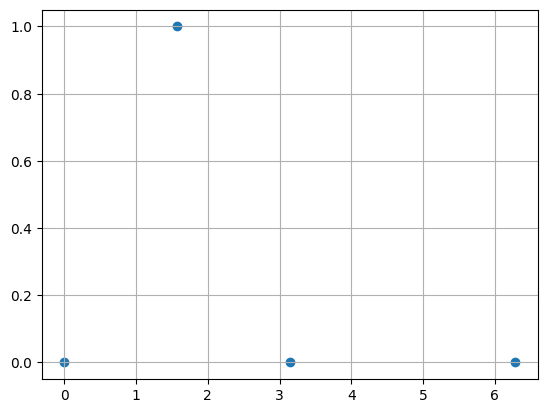

In [3]:
plt.figure(); plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1]); plt.grid()

Con esta nueva información actualizas tus creencias y reduces la cantidad de formas en las que se conectan estos puntos (siguen siendo infinitas).

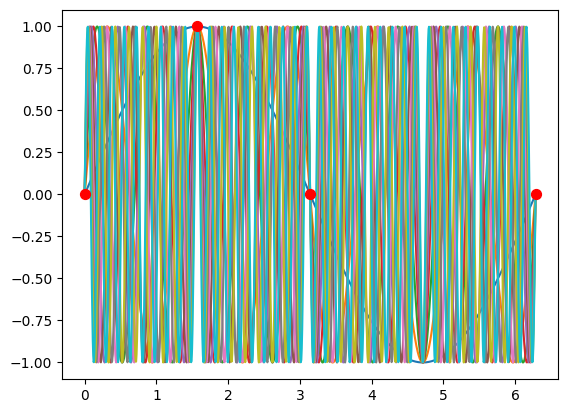

In [4]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(10) :
    y = np.sin((4*i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1], s=50, c="r", zorder=3)

Te pones a pensar: "Sí. Teóricamente hay infinitas funciones que pueden conectar estos puntos, pero sólo algunas tienen sentido dado mi contexto."

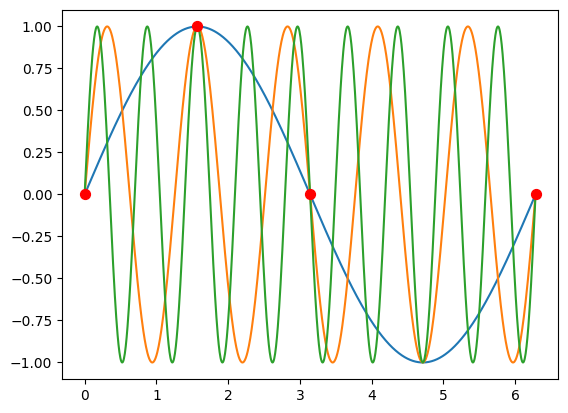

In [5]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(3) :
    y = np.sin((4*i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1], s=50, c="r", zorder=3)

Ahora sólo quedan algunos pocos candidatos dado el criterio que tienes. Hay incertidumbre sobre cuál de estos candidatos podría ser el que mejor se ajusta, así que decides pedir más información. ¿Qué información serviría más?
- Se podría pedir el valor de $y$ cuando $x=\frac{3\pi}{2}$, pero los candidatos que tenemos todos pasan por el mismo punto. Incluso si nos dieran la información, no ayudaría de mucho.
- Se podría pedir fuera del rango que tenemos, pero quizás la información no existe o dado el contexto del problema es imposible que estos puntos existan.

Nos asignan nuestro último punto.

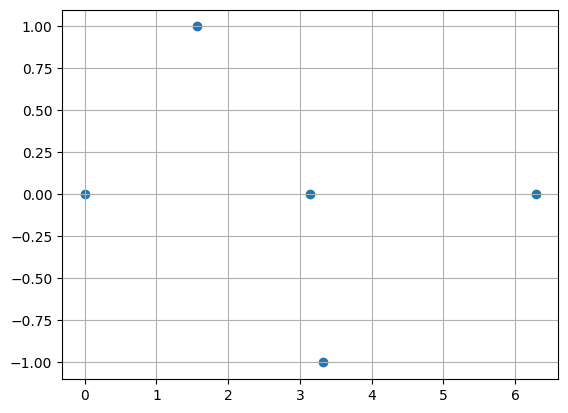

In [6]:
plt.figure(); plt.scatter([0, np.pi, 2*np.pi, np.pi/2, 19*np.pi/18], [0, 0, 0, 1, -1]); plt.grid()

Usamos esta nueva información (evidencia) junto con lo que conocíamos (anterior) y lo que creemos que es posible (verosimilitud) para decidir sobre una nueva función (posterior).

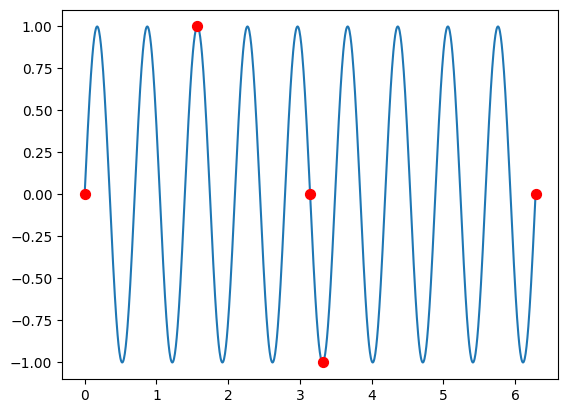

In [7]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); y = np.sin(9*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2, 19*np.pi/18], [0, 0, 0, 1, -1], s=50, c="r", zorder=3)

Una forma de realizar este experimento es mediante un proceso gaussiano, que asume que la variable de salida es una variable aleatoria con distribución normal multivariada. Utilicemos la función que encontramos y asumamos que no sabemos cuál es.

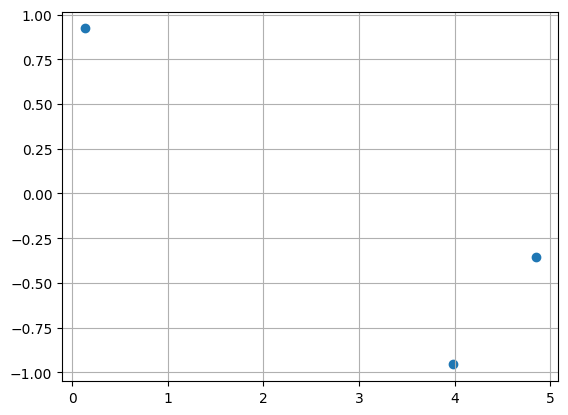

In [8]:
np.random.seed(10)
def f(x) :
    return np.sin(9*x)
X = np.random.uniform(0, 2*np.pi, 3).reshape([-1, 1])
plt.figure(); plt.scatter(X, f(X)); plt.grid()

Realizamos una regresión de proceso gaussiano para encontrar distribuciones que podrían darnos estas muestras

In [9]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

y = f(X).ravel()

kernel = 1.0 * RBF(length_scale=1.0)

gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gp.fit(X, y)

,"kernel kernel: kernel instance, default=NoneThe kernel specifying the covariance function of the GP. If None ispassed, the kernel ``ConstantKernel(1.0, constant_value_bounds=""fixed"")* RBF(1.0, length_scale_bounds=""fixed"")`` is used as default. Note thatthe kernel hyperparameters are optimized during fitting unless thebounds are marked as ""fixed"".",1**2 * RBF(length_scale=1)
,"alpha alpha: float or ndarray of shape (n_samples,), default=1e-10Value added to the diagonal of the kernel matrix during fitting.This can prevent a potential numerical issue during fitting, byensuring that the calculated values form a positive definite matrix.It can also be interpreted as the variance of additional Gaussianmeasurement noise on the training observations. Note that this isdifferent from using a `WhiteKernel`. If an array is passed, it musthave the same number of entries as the data used for fitting and isused as datapoint-dependent noise level. Allowing to specify thenoise level directly as a parameter is mainly for convenience andfor consistency with :class:`~sklearn.linear_model.Ridge`.For an example illustrating how the alpha parameter controlsthe noise variance in Gaussian Process Regression, see:ref:`sphx_glr_auto_examples_gaussian_process_plot_gpr_noisy_targets.py`.",1e-10
,"optimizer optimizer: ""fmin_l_bfgs_b"", callable or None, default=""fmin_l_bfgs_b""Can either be one of the internally supported optimizers for optimizingthe kernel's parameters, specified by a string, or an externallydefined optimizer passed as a callable. If a callable is passed, itmust have the signature:: def optimizer(obj_func, initial_theta, bounds): # * 'obj_func': the objective function to be minimized, which # takes the hyperparameters theta as a parameter and an # optional flag eval_gradient, which determines if the # gradient is returned additionally to the function value # * 'initial_theta': the initial value for theta, which can be # used by local optimizers # * 'bounds': the bounds on the values of theta .... # Returned are the best found hyperparameters theta and # the corresponding value of the target function. return theta_opt, func_minPer default, the L-BFGS-B algorithm from `scipy.optimize.minimize`is used. If None is passed, the kernel's parameters are kept fixed.Available internal optimizers are: `{'fmin_l_bfgs_b'}`.",'fmin_l_bfgs_b'
,"n_restarts_optimizer n_restarts_optimizer: int, default=0The number of restarts of the optimizer for finding the kernel'sparameters which maximize the log-marginal likelihood. The first runof the optimizer is performed from the kernel's initial parameters,the remaining ones (if any) from thetas sampled log-uniform randomlyfrom the space of allowed theta-values. If greater than 0, all boundsmust be finite. Note that `n_restarts_optimizer == 0` implies that onerun is performed.",10
,"normalize_y normalize_y: bool, default=FalseWhether or not to normalize the target values `y` by removing the meanand scaling to unit-variance. This is recommended for cases wherezero-mean, unit-variance priors are used. Note that, in thisimplementation, the normalisation is reversed before the GP predictionsare reported... versionchanged:: 0.23",False
,"copy_X_train copy_X_train: bool, default=TrueIf True, a persistent copy of the training data is stored in theobject. Otherwise, just a reference to the training data is stored,which might cause predictions to change if the data is modifiedexternally.",True
,"n_targets n_targets: int, default=NoneThe number of dimensions of the target values. Used to decide the numberof outputs when sampling from the prior distributions (i.e. calling:meth:`sample_y` before :meth:`fit`). This parameter is ignored once:meth:`fit` has been called... versionadded:: 1.3",None
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation used to initialize the centers.Pass an int for reproducible results across multiple function calls.See :term:`Glos

Creamos un vector de valores posibles de $x$ y predecimos $y$ usando el resultado de la regresión.

In [10]:
X_new = np.linspace(0, 2*np.pi, 1000).reshape([-1, 1])

y_pred, desv = gp.predict(X_new, return_std=True)

Graficamos nuestra primera propuesta, utilizando el error estándar para dibujar nuestros intervalos de confianza.

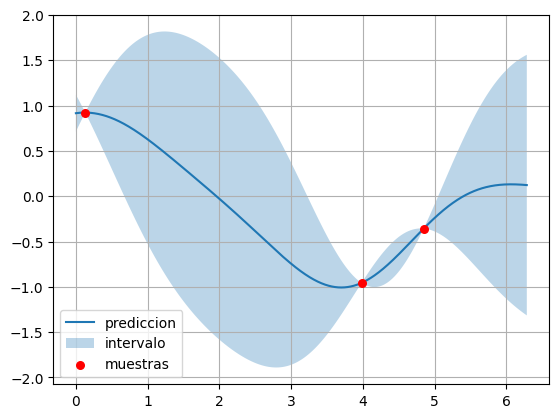

In [11]:
def graficar(X, y, X_new, y_pred, desv):
    plt.figure()
    plt.plot(X_new, y_pred, label="prediccion")
    plt.fill_between(X_new.ravel(), y_pred - 2*desv, y_pred + 2*desv, alpha=0.3, label="intervalo")
    plt.scatter(X, y, s=30, c="r", zorder=3, label="muestras")
    plt.grid()
    plt.legend()

graficar(X, y, X_new, y_pred, desv)
plt.show()

Con 3 puntos la prediccion pasa por las muestras, pero donde no hay datos el intervalo se abre muchisimo, entre 0 y 3 va como de -1.9 a 1.8. Ahi es donde menos sabe el modelo

Podemos ver que necesitamos más muestras debido a que hay mucha incertidumbre en algunas partes de nuestro dominio. Hay varios criterios para decidir cómo pedir muestras:
- Maximizar (busco mi predicción del máximo actual y pido esa medida)
- Minimizar (busco mi predicción del mínimo actual y pido esa medida)
- Reducir incertidumbre (busco el punto donde mi intervalo de confianza es más grande y pido esa medida)

In [12]:
# reducir incertidumbre, se pide donde el intervalo es mas grande

x_sig = X_new[np.argmax(desv)]
print("Siguiente punto:", x_sig)

X = np.vstack([X, x_sig])
y = f(X).ravel()

print(X.shape)

Siguiente punto: [1.98118456]
(4, 1)


Y repetimos el proceso ya con nueva información.

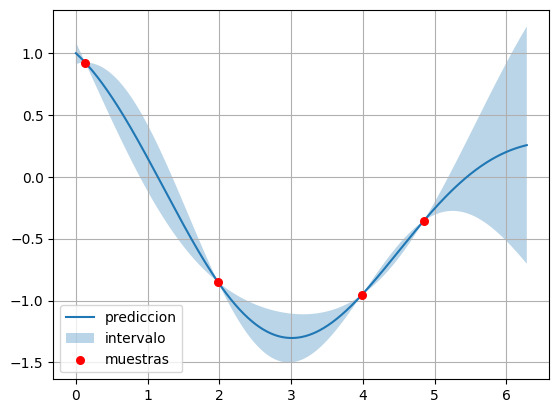

In [13]:
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gp.fit(X, y)

y_pred, desv = gp.predict(X_new, return_std=True)

graficar(X, y, X_new, y_pred, desv)
plt.show()

Se pidio el punto donde el intervalo era mas grande, x = 1.98, y con esa sola muestra el intervalo se cerro en esa zona. Lo que queda mas abierto ahora es la orilla derecha, donde no hay muestras

Repitamos el proceso 30 veces con una función distinta.

$$ f(x) = \sin{(\frac{x}{3})} + \cos{(2x)},\ \ \ \ x \in [-5\pi, 5\pi] $$

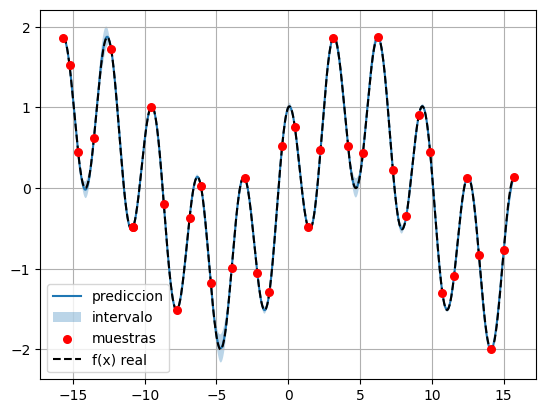

Error promedio: 0.004051263512901317


In [14]:
def f(x) :
    return np.sin(x/3) + np.cos(2*x)

np.random.seed(42)
X = np.random.uniform(-5*np.pi, 5*np.pi, 6).reshape([-1, 1])
y = f(X).ravel()

X_new = np.linspace(-5*np.pi, 5*np.pi, 1000).reshape([-1, 1])

for i in range(30):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(X, y)
    y_pred, desv = gp.predict(X_new, return_std=True)

    x_sig = X_new[np.argmax(desv)]
    X = np.vstack([X, x_sig])
    y = f(X).ravel()

gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gp.fit(X, y)
y_pred, desv = gp.predict(X_new, return_std=True)

graficar(X, y, X_new, y_pred, desv)
plt.plot(X_new, f(X_new), linestyle="--", c="k", label="f(x) real")
plt.legend()
plt.show()

print("Error promedio:", np.mean(np.abs(y_pred - f(X_new).ravel())))

Con 6 muestras iniciales y 30 mas pidiendo siempre donde hay mas incertidumbre, la prediccion queda casi encima de la funcion real, con un error promedio de 0.004. Las muestras quedan repartidas en todo el dominio

### Actividad

1. Modificar el comportamiento de selección para elegir el máximo de las predicciones como el siguiente punto.
2. Modificar el comportamiento de selección para elegir el mínimo de las predicciones como el siguiente punto.

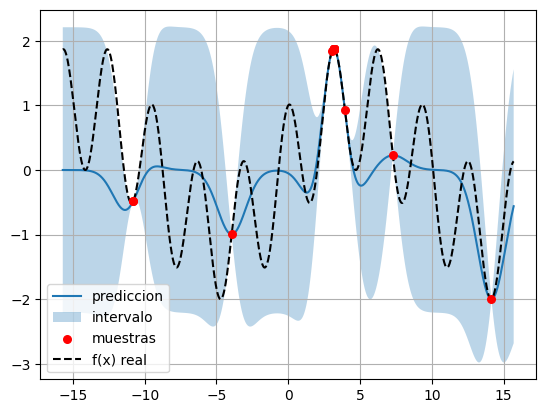

Maximo encontrado: x = 3.191908451845485  f(x) = 1.8692300867568992
Maximo real: 1.8694176347701237
Puntos distintos: 9 de 36
Error promedio: 0.6806171577214092


In [15]:
# 1. maximo de las predicciones

np.random.seed(42)
X = np.random.uniform(-5*np.pi, 5*np.pi, 6).reshape([-1, 1])
y = f(X).ravel()

for i in range(30):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(X, y)
    y_pred, desv = gp.predict(X_new, return_std=True)

    x_sig = X_new[np.argmax(y_pred)]
    X = np.vstack([X, x_sig])
    y = f(X).ravel()

gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gp.fit(X, y)
y_pred, desv = gp.predict(X_new, return_std=True)

graficar(X, y, X_new, y_pred, desv)
plt.plot(X_new, f(X_new), linestyle="--", c="k", label="f(x) real")
plt.legend()
plt.show()

print("Maximo encontrado: x =", X[np.argmax(y)][0], " f(x) =", y.max())
print("Maximo real:", f(X_new).max())
print("Puntos distintos:", len(np.unique(X)), "de", len(X))
print("Error promedio:", np.mean(np.abs(y_pred - f(X_new).ravel())))

Pidiendo siempre el maximo de la prediccion encontro 1.8692 cuando el real es 1.8694, casi exacto. Pero se queda pegado en una zona, de las 36 muestras solo 9 son puntos distintos, y el resto de la funcion no la aprende, el error promedio sube a 0.68

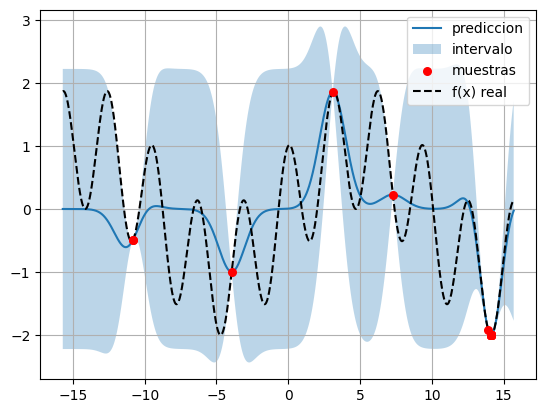

Minimo encontrado: x = 14.135594572458576  f(x) = -1.9999949179650427
Minimo real: -1.9999949179650427
Puntos distintos: 8 de 36
Error promedio: 0.674786288153148


In [16]:
# 2. minimo de las predicciones

np.random.seed(42)
X = np.random.uniform(-5*np.pi, 5*np.pi, 6).reshape([-1, 1])
y = f(X).ravel()

for i in range(30):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(X, y)
    y_pred, desv = gp.predict(X_new, return_std=True)

    x_sig = X_new[np.argmin(y_pred)]
    X = np.vstack([X, x_sig])
    y = f(X).ravel()

gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
gp.fit(X, y)
y_pred, desv = gp.predict(X_new, return_std=True)

graficar(X, y, X_new, y_pred, desv)
plt.plot(X_new, f(X_new), linestyle="--", c="k", label="f(x) real")
plt.legend()
plt.show()

print("Minimo encontrado: x =", X[np.argmin(y)][0], " f(x) =", y.min())
print("Minimo real:", f(X_new).min())
print("Puntos distintos:", len(np.unique(X)), "de", len(X))
print("Error promedio:", np.mean(np.abs(y_pred - f(X_new).ravel())))

Aqui es igual pero al reves, encontro el minimo de -2 en x = 14.14 con solo 8 puntos distintos de 36 y un error promedio de 0.67. Si solo quieres el mejor valor sirve pedir el maximo o el minimo, si quieres conocer toda la funcion conviene la incertidumbre

Ahora lo mismo pero para buscar hiperparametros. Se buscan C y gamma de un SVC con kernel rbf en el dataset Default. La funcion objetivo recibe H = [C, gamma], entrena con K-Fold de 5 y regresa el AUC promedio, y el proceso gaussiano decide que combinacion probar despues

In [17]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

datos = pd.read_csv("Default.csv")
datos["student"] = (datos["student"] == "Yes").astype(int)

X_default = datos[["balance", "income", "student"]]
y_default = (datos["default"] == "Yes").astype(int)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), ["balance", "income"]),
        ("bool", "passthrough", ["student"]),
    ]
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [18]:
def objetivo(H):
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("modelo", SVC(kernel="rbf", C=H[0], gamma=H[1]))])

    aucs = []
    for train_idx, test_idx in kf.split(X_default):
        pipeline.fit(X_default.iloc[train_idx], y_default.iloc[train_idx])
        # para el AUC sirve la distancia al hiperplano, no hace falta probability=True
        score = pipeline.decision_function(X_default.iloc[test_idx])
        aucs.append(roc_auc_score(y_default.iloc[test_idx], score))

    return np.mean(aucs)

In [19]:
# todas las combinaciones posibles de C en [0.1, 50] y gamma en [0.001, 1]

candidatos = []
for c in np.linspace(0.1, 50, 100):
    for g in np.linspace(0.001, 1, 100):
        candidatos.append([c, g])

H_new = np.array(candidatos)

# 5 combinaciones iniciales al azar

np.random.seed(42)
C_ini = np.random.uniform(0.1, 50, 5)
gamma_ini = np.random.uniform(0.001, 1, 5)

H = []
auc = []

for i in range(5):
    H.append([C_ini[i], gamma_ini[i]])
    auc.append(objetivo(H[i]))

print(len(H_new))
pd.DataFrame(H, columns=["C", "gamma"]).assign(AUC=auc).round(4)

10000


,C,gamma,AUC
0,18.7896,0.1568,0.8769
1,47.5406,0.0590,0.8577
2,36.6265,0.8663,0.8155
3,29.9731,0.6015,0.7756
4,7.8853,0.7084,0.7409


In [20]:
# un length_scale por columna porque C llega a 50 y gamma solo a 1

kernel_H = 1.0 * RBF(length_scale=[10.0, 0.1])

for i in range(30):
    gp = GaussianProcessRegressor(kernel=kernel_H, n_restarts_optimizer=10, normalize_y=True)
    gp.fit(np.array(H), auc)
    y_pred, desv = gp.predict(H_new, return_std=True)

    h_sig = H_new[np.argmax(y_pred + 2*desv)]
    H.append([h_sig[0], h_sig[1]])
    auc.append(objetivo(h_sig))

resultados = pd.DataFrame(H, columns=["C", "gamma"])
resultados["AUC"] = auc

print("Combinaciones probadas:", len(resultados))
print("Gammas distintas:", resultados["gamma"].round(4).nunique())
resultados.sort_values("AUC", ascending=False).head(5).round(4)

Combinaciones probadas: 35
Gammas distintas: 22


,C,gamma,AUC
7,0.1000,0.0010,0.9195
8,14.7172,0.0010,0.8896
20,35.3828,0.1221,0.8886
30,39.9192,0.1221,0.8871
24,41.4313,0.1019,0.8865


Cada vez se pide la combinacion con el y_pred + 2*desv mas alto, asi junta lo que se predice bueno con lo que todavia no conoce

De 35 combinaciones la mejor fue C = 0.1 y gamma = 0.001 con 0.9195 de AUC. Las 5 del inicio al azar sacaron entre 0.74 y 0.88, o sea que si mejoro, y probar todas serian 10000 combinaciones

La mejor quedo justo en la orilla, son el C y el gamma mas chicos que se permitian, puede que con valores mas chicos salga todavia mejor